In [1]:
from requirements import *

# Extended Data Figure 9

In [2]:
adata_cite = sc.read_h5ad(CITE)

## ED Figure 9c. CITE-seq CD4 and CD8 clonality by group


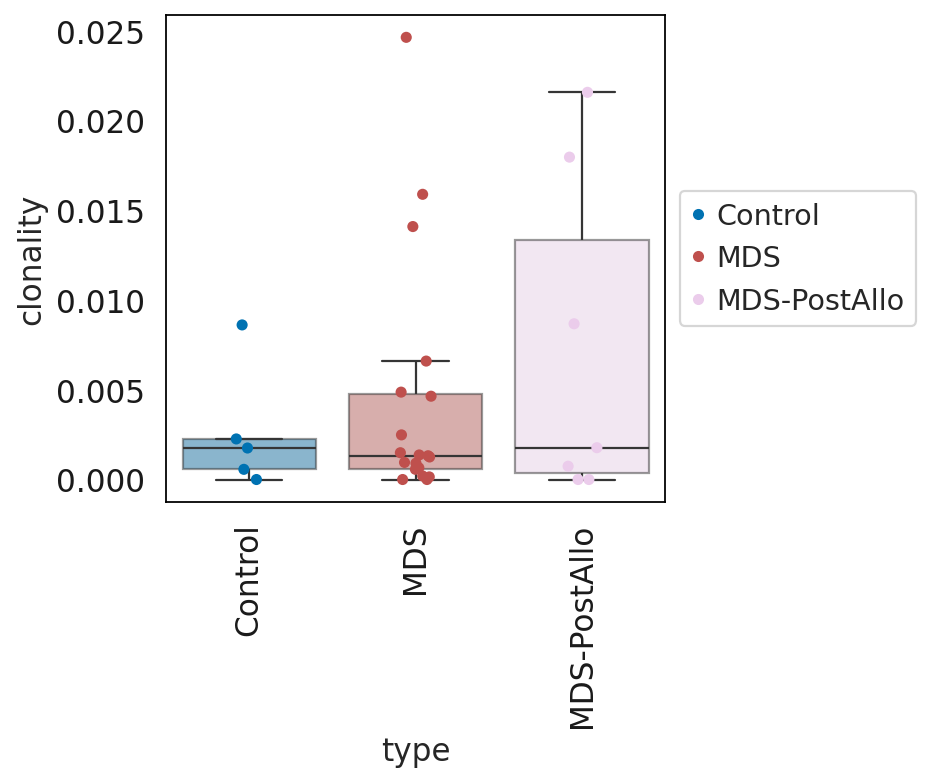

In [7]:
## CD4 Clonality

from scipy.stats import entropy

cts = ['CD4 FOXO1+', 'CD4 Memory', 'CD4 Naive/Central Memory', 'CD4 Treg']

tmp = adata_cite[(adata_cite.obs['ct_refined'].isin(cts))]
tmp =tmp[~(tmp.obs['tcr_size_prop'] == 'Unassigned')]
tmp.obs['type'][tmp.obs['type'].isin(['MDS-EB1','MDS-EB2'])] = 'MDS'
tmp = tmp[tmp.obs['type'].isin(['Control','MDS','MDS-PostAllo'])]

samplst = []
clonalities = []
for samp in tmp.obs['patient'].unique():
    currad = tmp[tmp.obs['patient'] == samp]
    if currad.obs.shape[0] >= 50 and not samp in ['ND44_T2','MDS_2_T3','ND41_T2']: # remove repeat samples
        tcrprops = [x for x in currad.obs['tcrb'].value_counts(normalize=True)]
        maxent = np.log2(len(tcrprops))
        c = (1 - entropy(tcrprops, base=2)/maxent)
        samplst.append(samp)
        clonalities.append(c)

di_type = dict(zip(tmp.obs['patient'], tmp.obs['type']))

df = pd.DataFrame({'sample': samplst, 'clonality': clonalities})
df['type'] = df['sample']
df = df.replace({'type': di_type})
sc.set_figure_params(figsize=(4, 4))

df.type = pd.Categorical(df.type, categories = ['Control','MDS','MDS-PostAllo'], ordered = True)

ax = sns.boxplot(data=df, x="type", y="clonality",
                 boxprops=dict(alpha=.5), showfliers=False, palette=["#0072B2","#BF504D","#ebcceb"])
ax.tick_params(axis='x', labelrotation=90)
sns.stripplot(data=df, x="type", y="clonality", hue = 'type', palette=["#0072B2","#BF504D","#ebcceb"],
              dodge=False, ax=ax)
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.show()

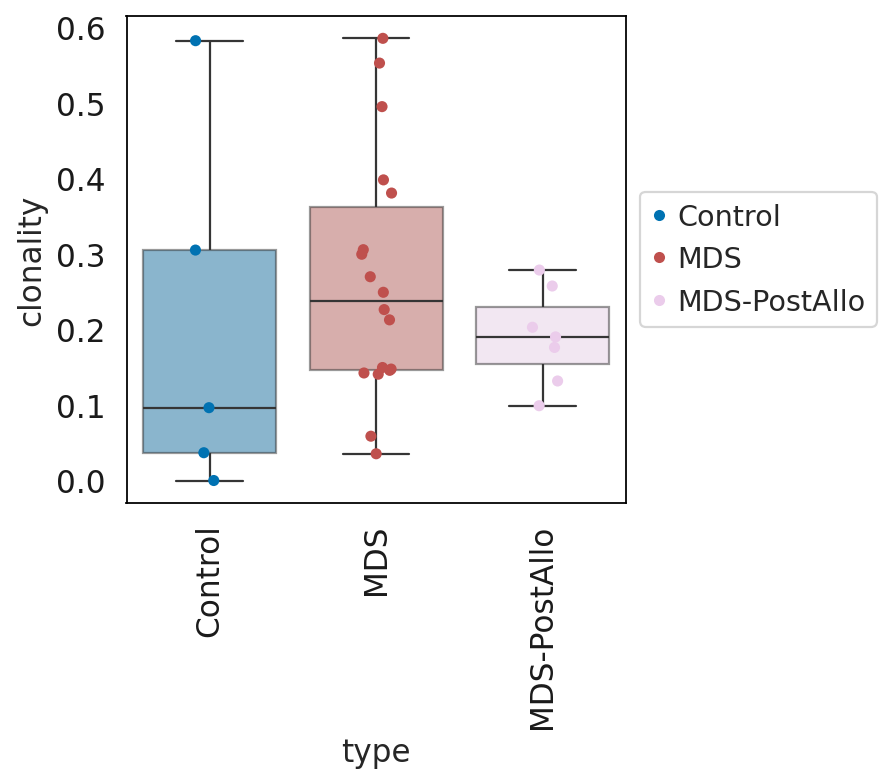

In [5]:
## CD8 Clonality

from scipy.stats import entropy

cts = ['CD8 TEMRA GZMB+',
 'CD8 Naive',
 'CD8 Effector Memory',
 'CD8 Memory GZMK+',
 'CD8 Memory TOX+',
 'CD8 MAIT',
 'CD8 TEMRA ISG+']

tmp = adata_cite[(adata_cite.obs['ct_refined'].isin(cts))]
tmp =tmp[~(tmp.obs['tcr_size_prop'] == 'Unassigned')]
tmp.obs['type'][tmp.obs['type'].isin(['MDS-EB1','MDS-EB2'])] = 'MDS'
tmp = tmp[tmp.obs['type'].isin(['Control','MDS','MDS-PostAllo'])]

samplst = []
clonalities = []
for samp in tmp.obs['patient'].unique():
    currad = tmp[tmp.obs['patient'] == samp]
    if currad.obs.shape[0] >= 50 and not samp in ['ND44_T2','MDS_2_T3','ND41_T2']: # remove repeat samples
        tcrprops = [x for x in currad.obs['tcrb'].value_counts(normalize=True)]
        maxent = np.log2(len(tcrprops))
        c = (1 - entropy(tcrprops, base=2)/maxent)
        samplst.append(samp)
        clonalities.append(c)

di_type = dict(zip(tmp.obs['patient'], tmp.obs['type']))
df = pd.DataFrame({'sample': samplst, 'clonality': clonalities})
df['type'] = df['sample']
df = df.replace({'type': di_type})
sc.set_figure_params(figsize=(4, 4))

df.type = pd.Categorical(df.type, categories = ['Control','MDS','MDS-PostAllo'], ordered = True)

ax = sns.boxplot(data=df, x="type", y="clonality",
                 boxprops=dict(alpha=.5), showfliers=False, palette=["#0072B2","#BF504D","#ebcceb"])
ax.tick_params(axis='x', labelrotation=90)
sns.stripplot(data=df, x="type", y="clonality", hue = 'type', palette=["#0072B2","#BF504D","#ebcceb"],
              dodge=False, ax=ax)
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.show()

## ED Figure 9d. CD4 TCR clone-size categories, Control vs MDS


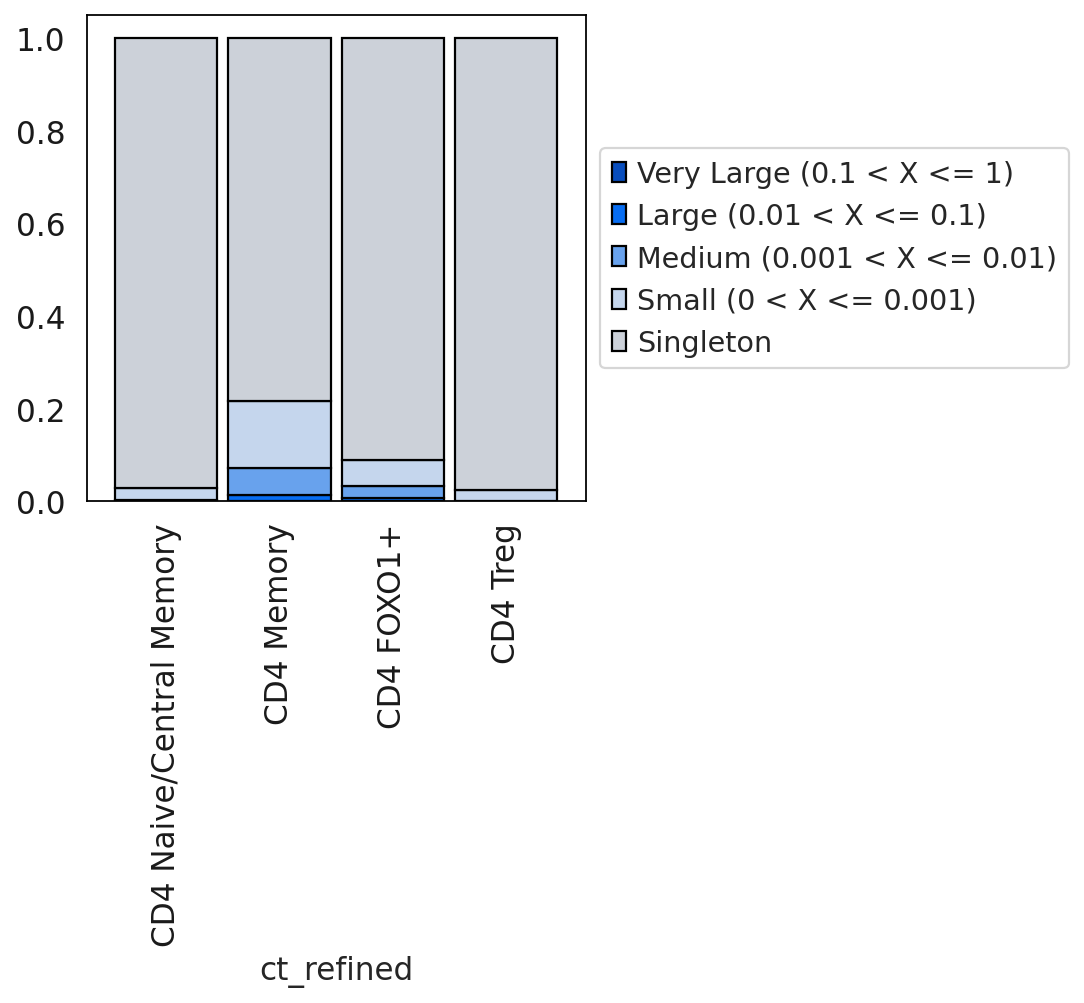

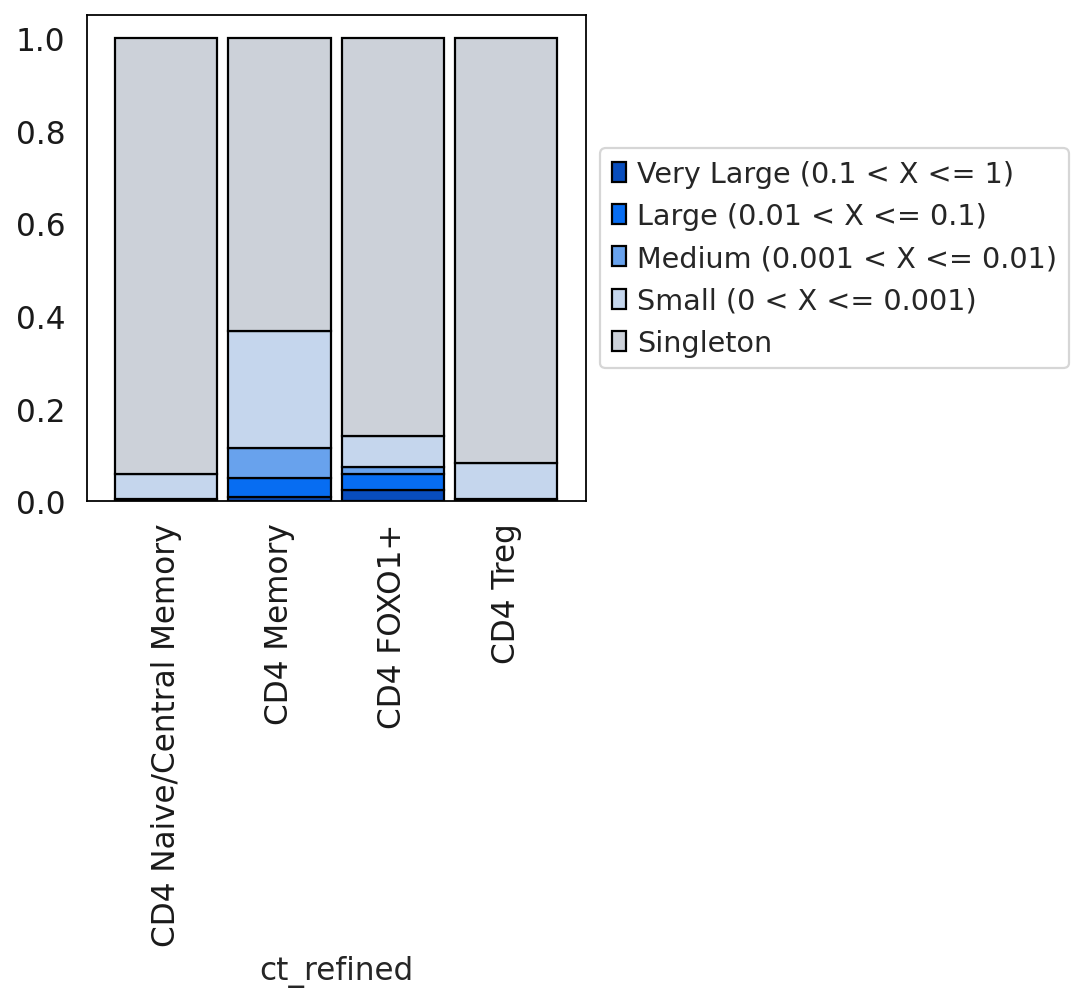

In [9]:
import matplotlib  
sc.set_figure_params(figsize=(4, 4))
matplotlib.rcParams['pdf.fonttype'] = 42

cts = ['CD4 FOXO1+', 'CD4 Memory', 'CD4 Naive/Central Memory', 'CD4 Treg']
tmp = adata_cite[(adata_cite.obs['ct_refined'].isin(cts))]
tmp.obs['tcr_size_prop'] = [str(x) for x in tmp.obs['tcr_size_prop']]
tmp.obs['tcr_size_prop'][tmp.obs['tcr_size_prop'] == 'Hyperexpanded (0.1 < X <= 1)'] = 'Very Large (0.1 < X <= 1)'
tmp =tmp[~(tmp.obs['tcr_size_prop'] == 'Unassigned')]


ad_ctl =tmp[(tmp.obs['type'].isin(['Control']))]
df = pd.crosstab(index=ad_ctl.obs['ct_refined'], columns=ad_ctl.obs['tcr_size_prop'])
df = df.reindex(['CD4 Naive/Central Memory','CD4 Memory','CD4 FOXO1+','CD4 Treg'])
df = df[['Very Large (0.1 < X <= 1)', 'Large (0.01 < X <= 0.1)', 'Medium (0.001 < X <= 0.01)', 'Small (0 < X <= 0.001)', 'Singleton']]

cmp = matplotlib.colors.ListedColormap(['#084dbd',"#076df2",  "#68a2ed","#c5d6ed", '#ccd1d9'])
df.apply(lambda x: x/x.sum(), axis=1).plot(kind='bar', stacked=True, width = 0.9,colormap= cmp,edgecolor='black')

plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.show()


ad_mds = tmp[(tmp.obs['type'].isin(['MDS','MDS-EB1','MDS-EB2']))]
df = pd.crosstab(index=ad_mds.obs['ct_refined'], columns=ad_mds.obs['tcr_size_prop'])
df = df.reindex(['CD4 Naive/Central Memory','CD4 Memory','CD4 FOXO1+','CD4 Treg'])
df = df[['Very Large (0.1 < X <= 1)', 'Large (0.01 < X <= 0.1)', 'Medium (0.001 < X <= 0.01)', 'Small (0 < X <= 0.001)', 'Singleton']]

cmp = matplotlib.colors.ListedColormap(['#084dbd',"#076df2",  "#68a2ed","#c5d6ed", '#ccd1d9'])
df.apply(lambda x: x/x.sum(), axis=1).plot(kind='bar', stacked=True, width = 0.9,colormap= cmp,edgecolor='black')

plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.show()

## ED Figure 9f. CD8 subset UMAP and TCR+ cells on the same UMAP


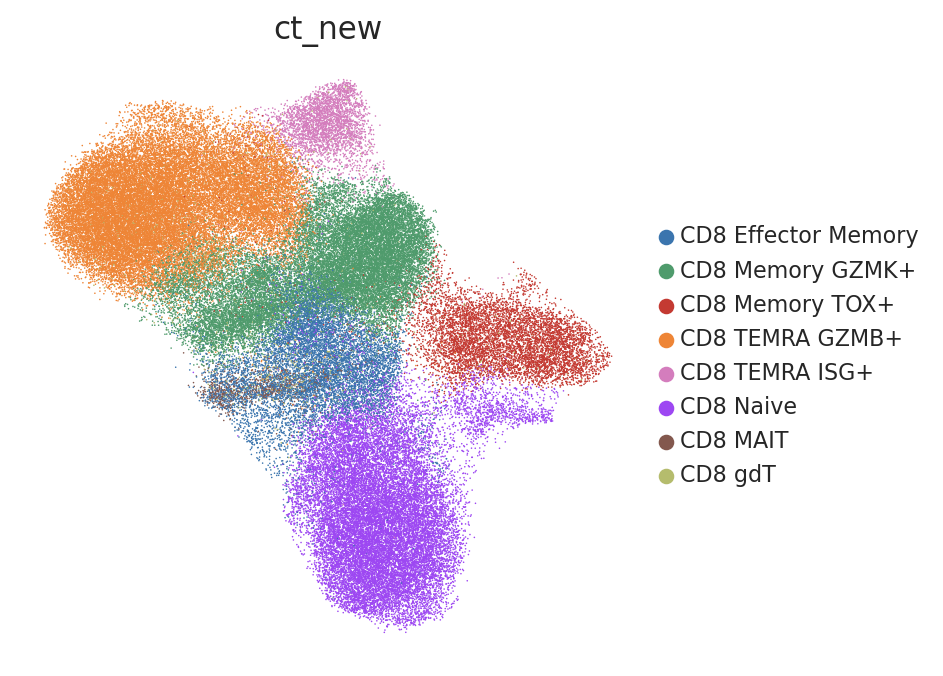

In [12]:
sc.set_figure_params(figsize=(5, 5))

colors = {'CD8 Effector Memory': "#3b75ae",
 'CD8 Memory GZMK+': "#4f9b6c",
 'CD8 Memory TOX+': "#c43a32", 
 'CD8 TEMRA GZMB+': "#ee8536",
 'CD8 TEMRA ISG+':"#d47dbd",
 'CD8 Naive': "#9d47f2",
 'CD8 MAIT': "#83584e",
 'CD8 gdT': "#b5bc6d",
         }
cd8.obs['ct_new'] = cd8.obs['ct_new'].astype('category')
cd8.obs['ct_new'] = cd8.obs['ct_new'].cat.reorder_categories(colors.keys())

sc.pl.umap(cd8,color= ['ct_new'], frameon=False, wspace=0.6, ncols=2,vmin = 120000/cd8.shape[0], vmax =5, sort_order = False, size = 2,
            legend_fontsize =10, palette=colors,) 


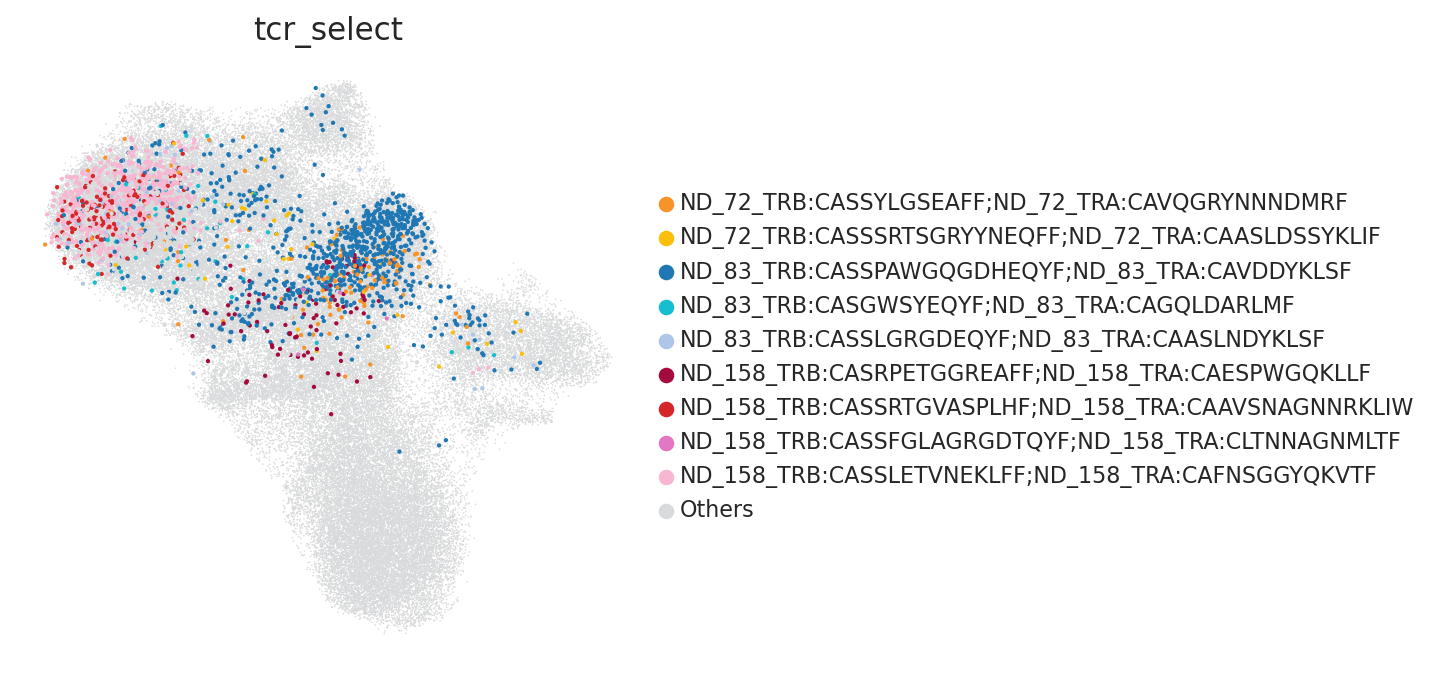

In [14]:
sc.set_figure_params(figsize=(5, 5))

tcrs = ['ND_72_TRB:CASSYLGSEAFF;ND_72_TRA:CAVQGRYNNNDMRF', 'ND_72_TRB:CASSSRTSGRYYNEQFF;ND_72_TRA:CAASLDSSYKLIF',
'ND_83_TRB:CASSPAWGQGDHEQYF;ND_83_TRA:CAVDDYKLSF', 'ND_83_TRB:CASGWSYEQYF;ND_83_TRA:CAGQLDARLMF', 'ND_83_TRB:CASSLGRGDEQYF;ND_83_TRA:CAASLNDYKLSF',
'ND_158_TRB:CASRPETGGREAFF;ND_158_TRA:CAESPWGQKLLF', 'ND_158_TRB:CASSRTGVASPLHF;ND_158_TRA:CAAVSNAGNNRKLIW',
'ND_158_TRB:CASSFGLAGRGDTQYF;ND_158_TRA:CLTNNAGNMLTF', 'ND_158_TRB:CASSLETVNEKLFF;ND_158_TRA:CAFNSGGYQKVTF']

tcrbs = [x.split(';')[0].split(':')[1] for x in tcrs]

cd8.obs['tcrpos'] = 'No'
cd8.obs['tcrpos'][cd8.obs['tcrb'].isin(tcrbs)] = 'Yes'

cd8.obs['ptsize'] =  2 
cd8.obs['ptsize'][cd8.obs['tcrpos'] == 'Yes'] = 15
cd8 = cd8[cd8.obs.ptsize.sort_values().index,:]

colors = {'ND_83_TRB:CASSPAWGQGDHEQYF;ND_83_TRA:CAVDDYKLSF': '#1f77b4',
          'ND_83_TRB:CASSLGRGDEQYF;ND_83_TRA:CAASLNDYKLSF': '#17becf',
          'ND_83_TRB:CASGWSYEQYF;ND_83_TRA:CAGQLDARLMF': '#aec7e8',
          'ND_158_TRB:CASRPETGGREAFF;ND_158_TRA:CAESPWGQKLLF': '#a30b3e',
          'ND_158_TRB:CASSRTGVASPLHF;ND_158_TRA:CAAVSNAGNNRKLIW': '#d62728',
          'ND_158_TRB:CASSLETVNEKLFF;ND_158_TRA:CAFNSGGYQKVTF': '#e377c2',
          'ND_72_TRB:CASSYLGSEAFF;ND_72_TRA:CAVQGRYNNNDMRF': '#f79328',
          'ND_72_TRB:CASSSRTSGRYYNEQFF;ND_72_TRA:CAASLDSSYKLIF': '#fabf0c',
          'ND_72_TRB:CATSSRQGGYEQYF;ND_72_TRA:CALTQGGYSTLTF': '#fff0ba',
          'Others': '#d9dadb'}

colors = {'ND_83_TRB:CASSPAWGQGDHEQYF;ND_83_TRA:CAVDDYKLSF': '#1f77b4',
          'ND_83_TRB:CASSLGRGDEQYF;ND_83_TRA:CAASLNDYKLSF': '#17becf',
          'ND_83_TRB:CASGWSYEQYF;ND_83_TRA:CAGQLDARLMF': '#aec7e8',
          
          'ND_158_TRB:CASRPETGGREAFF;ND_158_TRA:CAESPWGQKLLF': '#a30b3e',
          'ND_158_TRB:CASSRTGVASPLHF;ND_158_TRA:CAAVSNAGNNRKLIW': '#d62728',
          'ND_158_TRB:CASSLETVNEKLFF;ND_158_TRA:CAFNSGGYQKVTF': '#e377c2',
          'ND_158_TRB:CASSFGLAGRGDTQYF;ND_158_TRA:CLTNNAGNMLTF': '#f7b6d2',
          'ND_72_TRB:CASSYLGSEAFF;ND_72_TRA:CAVQGRYNNNDMRF': '#f79328',
          'ND_72_TRB:CASSSRTSGRYYNEQFF;ND_72_TRA:CAASLDSSYKLIF': '#fabf0c',
          'Others': '#d9dadb'}
colors = {'ND_72_TRB:CASSYLGSEAFF;ND_72_TRA:CAVQGRYNNNDMRF': '#f79328',
          'ND_72_TRB:CASSSRTSGRYYNEQFF;ND_72_TRA:CAASLDSSYKLIF': '#fabf0c',
          'ND_83_TRB:CASSPAWGQGDHEQYF;ND_83_TRA:CAVDDYKLSF': '#1f77b4',
          'ND_83_TRB:CASGWSYEQYF;ND_83_TRA:CAGQLDARLMF': '#17becf',
          'ND_83_TRB:CASSLGRGDEQYF;ND_83_TRA:CAASLNDYKLSF': '#aec7e8',
          'ND_158_TRB:CASRPETGGREAFF;ND_158_TRA:CAESPWGQKLLF': '#a30b3e',
          'ND_158_TRB:CASSRTGVASPLHF;ND_158_TRA:CAAVSNAGNNRKLIW': '#d62728',
          'ND_158_TRB:CASSFGLAGRGDTQYF;ND_158_TRA:CLTNNAGNMLTF': '#e377c2',
          'ND_158_TRB:CASSLETVNEKLFF;ND_158_TRA:CAFNSGGYQKVTF': '#f7b6d2',
        'Others': '#d9dadb'}

cd8.obs['tcr_select'] = 'Others'
for tcr in colors.keys():
    if not tcr == 'Others':
        alpha = tcr.split('TRA:')[1]
        beta = tcr.split('TRB:')[1].split(';')[0]
        tcrcells = [j for i,j in enumerate(cd8.obs['tcr'].index) if (alpha in str(cd8.obs['tcr'][i])) and (beta in str(cd8.obs['tcr'][i]))]
        cd8.obs['tcr_select'][cd8.obs.index.isin(tcrcells)] = tcr
cd8.obs['tcr_select'] = cd8.obs['tcr_select'].astype('category')
cd8.obs['tcr_select'] = cd8.obs['tcr_select'].cat.reorder_categories(colors.keys())
     
sc.pl.umap(cd8,color= ['tcr_select'],size = cd8.obs['ptsize'], 
          frameon=False, wspace=0.6, ncols=2,vmin = 120000/cd8.shape[0], vmax =5, sort_order = False, 
            legend_fontsize =10, palette=colors)
